In [11]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
SHOTS = 100

### Predictions

A qubit starts in the state \(|0\rangle\). Applying quantum gates can change its state and the probabilities of its measurement outcomes.

- **Circuit A:** Apply an H gate followed by an RY gate with an angle of \(\pi/3\). I predict that outcome 0 will occur more frequently, with approximately 93.3% zeros and 6.7% ones.
- **Circuit B:** Apply an H gate followed by an RY gate with an angle of \(-\pi/3\). I predict that outcome 1 will occur more frequently, with approximately 6.7% zeros and 93.3% ones.
- **Circuit C:** Apply an RY gate with an angle of \(\pi/3\). I predict approximately 75% zeros and 25% ones.

Actual results may vary slightly because measurements are sampled over 100 shots.

In [12]:
import numpy as np

# Circuit A: Outcome 0 is more likely
qc_a = QuantumCircuit(1, 1)
qc_a.h(0)
qc_a.ry(np.pi / 3, 0)
qc_a.measure(0, 0)

# Circuit B: Outcome 1 is more likely
qc_b = QuantumCircuit(1, 1)
qc_b.h(0)
qc_b.ry(-np.pi / 3, 0)
qc_b.measure(0, 0)

# Circuit C: A different degree of bias
qc_c = QuantumCircuit(1, 1)
qc_c.ry(np.pi / 3, 0)
qc_c.measure(0, 0)

Circuit A: 0 occurs more frequently


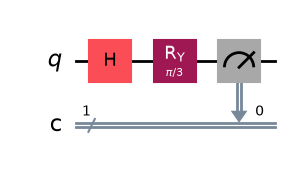

Circuit B: 1 occurs more frequently


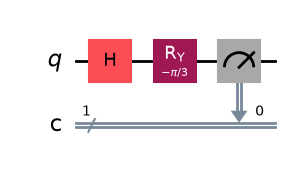

Circuit C: Alternative bias


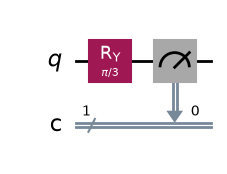

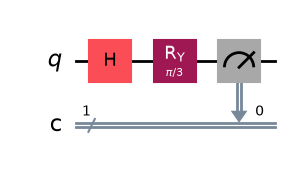

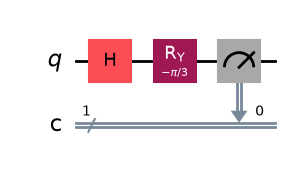

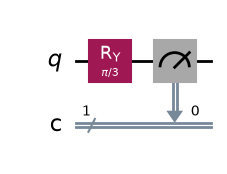

In [13]:
print("Circuit A: 0 occurs more frequently")
display(qc_a.draw("mpl"))

print("Circuit B: 1 occurs more frequently")
display(qc_b.draw("mpl"))

print("Circuit C: Alternative bias")
display(qc_c.draw("mpl"))

In [14]:
circuits = {
    "Circuit A - More zeros": qc_a,
    "Circuit B - More ones": qc_b,
    "Circuit C - 75% zeros": qc_c
}

results = {}

for name, circuit in circuits.items():
    job = simulator.run(circuit, shots=SHOTS)
    counts = job.result().get_counts()
    results[name] = counts

    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    print(f"\n{name}")
    print("Measurement counts:", counts)
    print(f"Zeros: {zeros}/100 ({zeros}%)")
    print(f"Ones: {ones}/100 ({ones}%)")


Circuit A - More zeros
Measurement counts: {'1': 96, '0': 4}
Zeros: 4/100 (4%)
Ones: 96/100 (96%)

Circuit B - More ones
Measurement counts: {'0': 93, '1': 7}
Zeros: 93/100 (93%)
Ones: 7/100 (7%)

Circuit C - 75% zeros
Measurement counts: {'0': 75, '1': 25}
Zeros: 75/100 (75%)
Ones: 25/100 (25%)


In [15]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

In [16]:
%matplotlib inline

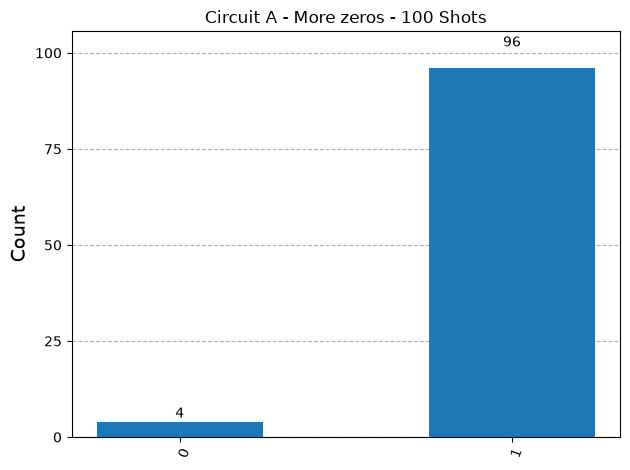

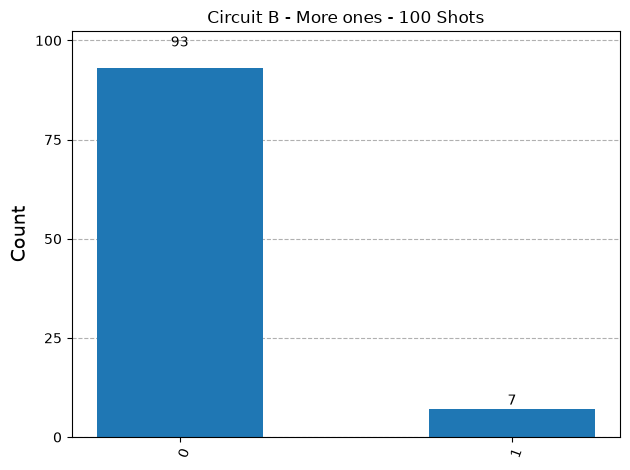

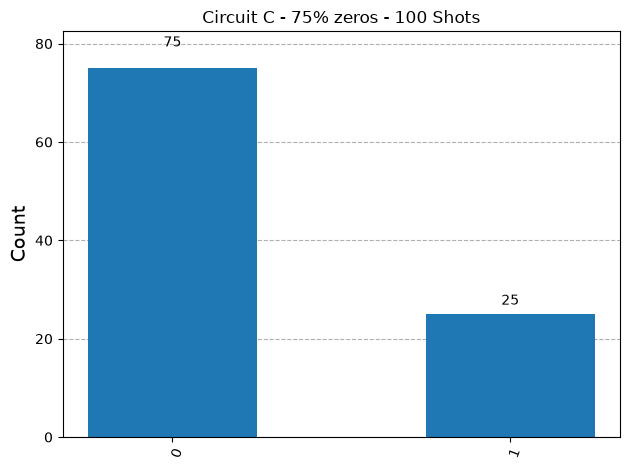

In [17]:
for name, counts in results.items():
    fig = plot_histogram(
        counts,
        title=f"{name} - 100 Shots"
    )
    plt.show()

In [18]:
predictions = {
    "Circuit A - More zeros": "0: 93.3%, 1: 6.7%",
    "Circuit B - More ones": "0: 6.7%, 1: 93.3%",
    "Circuit C - 75% zeros": "0: 75%, 1: 25%"
}

for name, counts in results.items():
    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    print(f"\n{name}")
    print("Predicted:", predictions[name])
    print(f"Actual: 0 = {zeros}%, 1 = {ones}%")


Circuit A - More zeros
Predicted: 0: 93.3%, 1: 6.7%
Actual: 0 = 4%, 1 = 96%

Circuit B - More ones
Predicted: 0: 6.7%, 1: 93.3%
Actual: 0 = 93%, 1 = 7%

Circuit C - 75% zeros
Predicted: 0: 75%, 1: 25%
Actual: 0 = 75%, 1 = 25%


### Comparison and Explanation

The experiment demonstrates that quantum gates can control measurement probabilities.

- **Circuit A:** The Hadamard gate creates an equal superposition. The subsequent RY rotation changes the relative amplitudes, making outcome 0 more likely.
- **Circuit B:** Changing the rotation angle changes the relative amplitudes in the opposite direction, making outcome 1 more likely.
- **Circuit C:** Applying only an RY gate to the initial state \(|0\rangle\) creates a biased superposition with a higher probability of measuring 0.

The actual counts may differ slightly from theoretical probabilities because only 100 measurements are performed. Changing the rotation angle changes the probability distribution.

### Challenge Question: How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

Quantum gates change the quantum state of a qubit by modifying its probability amplitudes and relative phase. When a qubit is measured, the probability of obtaining 0 is the squared magnitude of the amplitude of \(|0\rangle\), and the probability of obtaining 1 is the squared magnitude of the amplitude of \(|1\rangle\). For example, the Hadamard gate creates an equal superposition with a 50% probability of each outcome. Rotation gates such as RY can change the amplitudes and produce unequal probabilities. Therefore, by choosing appropriate quantum gates and rotation angles, we can control the measurement distribution.